# Análisis Exploratorio de Datos (EDA) - Mantenimiento Predictivo Industrial (AI4I 2020)

## 1. Contexto del Problema y Objetivos del Análisis
En la industria moderna (Industria 4.0), las paradas no programadas de maquinaria provocan pérdidas económicas millonarias, cuellos de botella en las líneas de producción y riesgos de seguridad. El **Mantenimiento Predictivo (PdM)** busca anticiparse a las averías mecánicas monitorizando en tiempo real variables de operación (temperatura, velocidad, par motor, desgaste) para intervenir antes de que ocurra una parada no planificada.

Este dataset (**AI4I 2020 Predictive Maintenance Dataset**, publicado por Stephan Matzka) simula una fresadora/torno industrial y reproduce con fidelidad los procesos físicos y modos de falla típicos del sector manufacturero.

### Objetivos Clave de este Análisis:
1. **Cuantificar la incidencia de fallos:** Evaluar la proporción exacta de fallos frente a operación normal (desbalance de clases).
2. **Caracterizar los modos de fallo:** Analizar los 5 tipos de averías específicas (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`), sus co-ocurrencias e inconsistencias en las etiquetas.
3. **Analizar las variables de operación:** Estudiar el comportamiento de las variables de sensores (temperaturas, velocidad de rotación, par y desgaste de herramienta).
4. **Ingeniería de Características Física (Domain-Specific Feature Engineering):** Identificar las leyes físicas que rigen cada fallo (potencia mecánica, sobreesfuerzo, disipación térmica) para derivar variables con alta capacidad predictiva.
5. **Definir la Estrategia de Modelado:** Determinar la métrica de negocio adecuada, prevención de fugas de información (*data leakage*), técnicas de balanceo y la arquitectura óptima para un modelo predictivo anticipatorio.


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve
)

warnings.filterwarnings('ignore')

# Configuración visual global
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['figure.autolayout'] = True
sns.set_theme(style='whitegrid', palette='muted')

PALETTE_BINARY = {0: '#2b5c8f', 1: '#d9534f', '0': '#2b5c8f', '1': '#d9534f'}  # Azul = Normal, Rojo = Fallo
PALETTE_LIST = ['#2b5c8f', '#d9534f']


## 2. Carga e Inspección Estructural del Dataset

El conjunto de datos consta de 10,000 registros y 14 columnas:
- **Identificadores:** `UDI` (índice continuo 1-10000) y `Product ID` (variante + número de serie).
- **Variante de calidad:** `Type` con categorías **L** (Low - 50%), **M** (Medium - 30%) y **H** (High - 20%).
- **Sensores continuos:**
  - `Air temperature [K]`: Temperatura ambiente.
  - `Process temperature [K]`: Temperatura de proceso.
  - `Rotational speed [rpm]`: Velocidad angular de rotación.
  - `Torque [Nm]`: Par de torsión aplicado.
  - `Tool wear [min]`: Tiempo acumulado de desgaste de la herramienta de corte.
- **Variable objetivo global:** `Machine failure` (0: Funcionamiento normal, 1: Avería).
- **Modos de falla específicos:** `TWF`, `HDF`, `PWF`, `OSF`, `RNF`.


In [2]:
# Localización robusta del dataset
data_path = '../data/ai4i2020.csv' if os.path.exists('../data/ai4i2020.csv') else 'data/ai4i2020.csv'
df = pd.read_csv(data_path)

print(f"Dimensiones del dataset: {df.shape[0]} filas x {df.shape[1]} columnas")
print(f"Valores nulos en el dataset: {df.isnull().sum().sum()}")
print(f"Filas duplicadas: {df.duplicated().sum()}")

# Inspección de tipos de datos y primeras filas
df.info()
df.head()


Dimensiones del dataset: 10000 filas x 14 columnas
Valores nulos en el dataset: 0
Filas duplicadas: 0
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null 

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 3. Análisis de la Variable Objetivo: Magnitud del Fallo y Desbalance Severo

Una de las características más críticas en el mantenimiento predictivo industrial es el **desbalance extremo de clases**. Las máquinas operan de manera correcta la inmensa mayoría del tiempo, y las averías representan eventos escasos pero de consecuencias severas.

A continuación cuantificamos cuántos fallos han ocurrido en relación al funcionamiento normal.


--- RESUMEN DE LA VARIABLE OBJETIVO ---
              Estado  Casos  Porcentaje (%)               Ratio
Operación Normal (0)   9661           96.61 1 por cada 1.04 ops
Fallo de Máquina (1)    339            3.39 1 por cada 29.5 ops


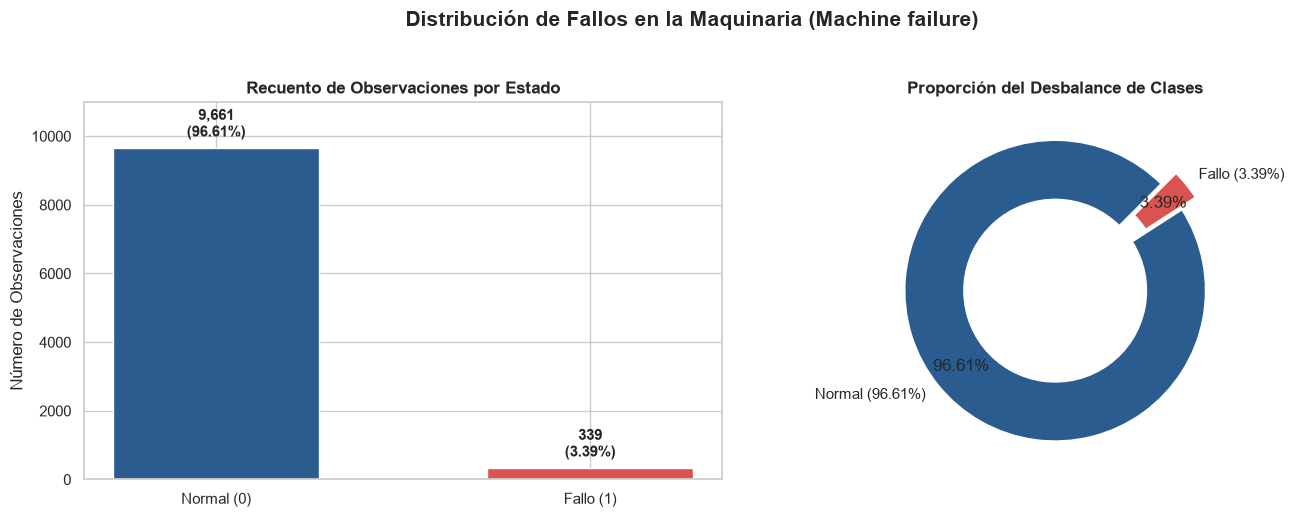

In [3]:
# Frecuencia absoluta y relativa de Machine failure
target_counts = df['Machine failure'].value_counts()
target_props = df['Machine failure'].value_counts(normalize=True) * 100

summary_target = pd.DataFrame({
    'Estado': ['Operación Normal (0)', 'Fallo de Máquina (1)'],
    'Casos': target_counts.values,
    'Porcentaje (%)': target_props.values,
    'Ratio': [f"1 por cada {len(df)/target_counts[0]:.2f} ops", f"1 por cada {len(df)/target_counts[1]:.1f} ops"]
})
print("--- RESUMEN DE LA VARIABLE OBJETIVO ---")
print(summary_target.to_string(index=False))

# Visualización gráfica del desbalance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Gráfico de barras con anotaciones
bars = axes[0].bar(['Normal (0)', 'Fallo (1)'], target_counts.values, color=['#2b5c8f', '#d9534f'], width=0.55)
axes[0].set_title('Recuento de Observaciones por Estado', fontweight='bold')
axes[0].set_ylabel('Número de Observaciones')
axes[0].set_ylim(0, 11000)

for bar in bars:
    height = bar.get_height()
    pct = (height / len(df)) * 100
    axes[0].annotate(f'{height:,}\n({pct:.2f}%)',
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 5), textcoords='offset points',
                     ha='center', va='bottom', fontweight='bold', fontsize=11)

# 2. Donut chart
colors = ['#2b5c8f', '#d9534f']
axes[1].pie(target_counts.values, labels=['Normal (96.61%)', 'Fallo (3.39%)'],
            colors=colors, autopct='%1.2f%%', startangle=45, pctdistance=0.8,
            explode=[0, 0.12], wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2))
axes[1].set_title('Proporción del Desbalance de Clases', fontweight='bold')

plt.suptitle('Distribución de Fallos en la Maquinaria (Machine failure)', fontsize=15, fontweight='bold', y=1.03)
plt.show()


### Hallazgo Clave 1: Implicaciones del Desbalance (3.39% de Fallos)
1. **Ratio de Desbalance:** Hay **9,661 casos normales** frente a **339 fallos**, lo que equivale a una proporción de aproximadamente **28.5 a 1**.
2. **La Paradoja de la Precisión (Accuracy Paradox):** Un modelo trivial ("dummy") que prediga sistemáticamente que la máquina nunca falla alcanzaría un **96.61% de exactitud (Accuracy)**, pero tendría una tasa de detección de fallos del **0% (Recall = 0)**. 
3. **Métricas obligatorias para el modelo:** En este contexto, la métrica **Accuracy queda totalmente descartada**. Se debe evaluar mediante **PR-AUC (Precision-Recall AUC)**, **ROC-AUC**, y **F2-Score** (dando el doble de importancia al Recall para minimizar falsos negativos).

---

## 4. Desglose Detallado de los Modos de Fallo y Detección de Discrepancias

El dataset no solo indica si hubo fallo general, sino que cataloga 5 modos de avería independientes:
1. **HDF (Heat Dissipation Failure - Disipación de Calor):** Falla en el sistema de refrigeración.
2. **OSF (Overstrain Failure - Sobreesfuerzo):** Torsión combinada con desgaste que sobrepasa el límite del material.
3. **PWF (Power Failure - Fallo de Potencia):** Potencia consumida fuera de los rangos operativos seguros.
4. **TWF (Tool Wear Failure - Desgaste de Herramienta):** Agotamiento de la vida útil del filo de corte.
5. **RNF (Random Failure - Fallo Aleatorio):** Evento estocástico sin causa física previa detectable.


--- DESGLOSE POR MODO DE FALLO ESPECÍFICO ---
Modo                                   Descripción  Total Casos  Frecuencia (%)  Proporción sobre el total de fallos (%)
 HDF Heat Dissipation Failure (Disipación Térmica)          115            1.15                                33.923304
 OSF            Overstrain Failure (Sobreesfuerzo)           98            0.98                                28.908555
 PWF             Power Failure (Fallo de Potencia)           95            0.95                                28.023599
 TWF      Tool Wear Failure (Desgaste Herramienta)           46            0.46                                13.569322
 RNF              Random Failure (Fallo Aleatorio)           19            0.19                                 5.604720

--- ANOMALÍAS E INCONSISTENCIAS EN LAS ETIQUETAS ---
1. Fallos aleatorios (RNF=1) donde Machine failure = 0: 18 casos de 19!
2. Casos con Machine failure = 1 pero NINGÚN modo activo (0 modos): 9 casos
3. Casos con fallo múltipl

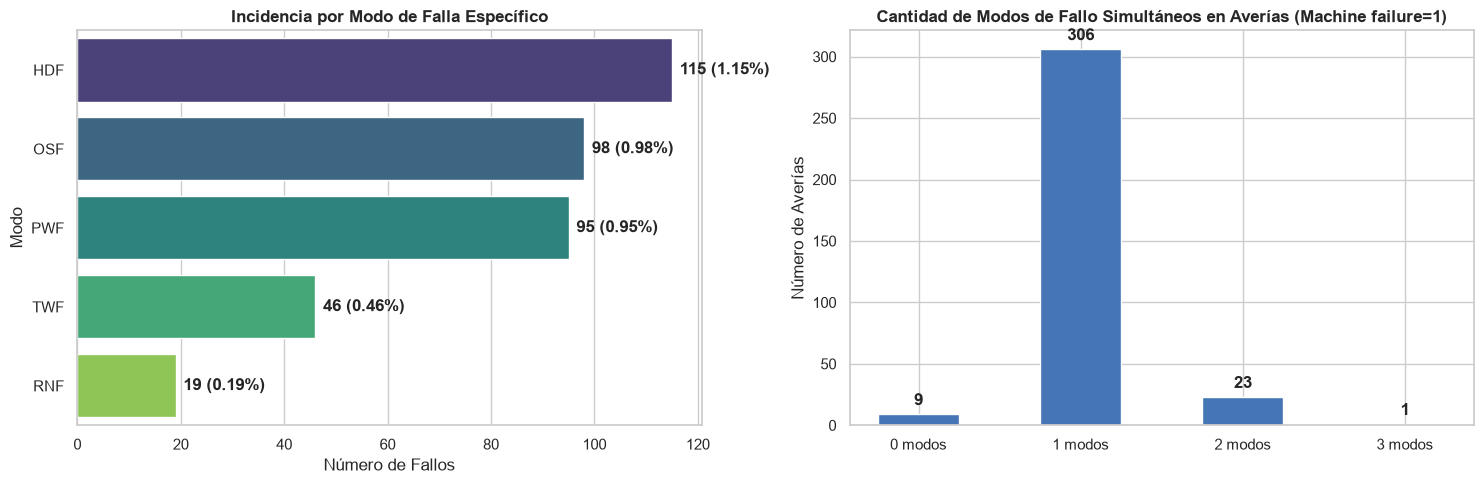

In [4]:
failure_modes = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']

# Tabla de frecuencias de los modos de fallo
mode_counts = df[failure_modes].sum()
mode_props = df[failure_modes].mean() * 100
mode_names = {
    'HDF': 'Heat Dissipation Failure (Disipación Térmica)',
    'OSF': 'Overstrain Failure (Sobreesfuerzo)',
    'PWF': 'Power Failure (Fallo de Potencia)',
    'TWF': 'Tool Wear Failure (Desgaste Herramienta)',
    'RNF': 'Random Failure (Fallo Aleatorio)'
}

failure_summary = pd.DataFrame({
    'Modo': mode_counts.index,
    'Descripción': [mode_names[m] for m in mode_counts.index],
    'Total Casos': mode_counts.values,
    'Frecuencia (%)': mode_props.values,
    'Proporción sobre el total de fallos (%)': (mode_counts.values / target_counts[1]) * 100
}).sort_values('Total Casos', ascending=False)

print("--- DESGLOSE POR MODO DE FALLO ESPECÍFICO ---")
print(failure_summary.to_string(index=False))

# Análisis de fallos múltiples y discrepancias
df['Total_Modes_Active'] = df[failure_modes].sum(axis=1)

# Discrepancias
rnf_no_failure = df[(df['Machine failure'] == 0) & (df['RNF'] == 1)].shape[0]
failure_no_modes = df[(df['Machine failure'] == 1) & (df['Total_Modes_Active'] == 0)].shape[0]
multi_failures = (df['Total_Modes_Active'] > 1).sum()

print("\n--- ANOMALÍAS E INCONSISTENCIAS EN LAS ETIQUETAS ---")
print(f"1. Fallos aleatorios (RNF=1) donde Machine failure = 0: {rnf_no_failure} casos de 19!")
print(f"2. Casos con Machine failure = 1 pero NINGÚN modo activo (0 modos): {failure_no_modes} casos")
print(f"3. Casos con fallo múltiple simultáneo (>1 modo activo): {multi_failures} casos")

# Visualización de modos de fallo
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico de barras horizontal por modo
sns.barplot(data=failure_summary, y='Modo', x='Total Casos', palette='viridis', ax=axes[0])
axes[0].set_title('Incidencia por Modo de Falla Específico', fontweight='bold')
axes[0].set_xlabel('Número de Fallos')
for i, v in enumerate(failure_summary['Total Casos']):
    axes[0].text(v + 1.5, i, f"{v} ({failure_summary['Frecuencia (%)'].iloc[i]:.2f}%)", va='center', fontweight='bold')

# Gráfico de número de modos activos por registro averiado
failures_only = df[df['Machine failure'] == 1]
mode_dist = failures_only['Total_Modes_Active'].value_counts().sort_index()
bars_m = axes[1].bar([f'{k} modos' for k in mode_dist.index], mode_dist.values, color='#4575b4', width=0.5)
axes[1].set_title('Cantidad de Modos de Fallo Simultáneos en Averías (Machine failure=1)', fontweight='bold')
axes[1].set_ylabel('Número de Averías')
for bar in bars_m:
    axes[1].annotate(f'{bar.get_height()}',
                     xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                     xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


### Hallazgo Clave 2: Inconsistencias y Alerta de Fuga de Datos (*Data Leakage*)
1. **HDF y OSF son los modos dominantes:** Entre ambos representan más del 62% de todos los fallos mecánicos.
2. **Inconsistencia de RNF:** De los 19 casos con `RNF = 1`, **18 no registraron parada (`Machine failure = 0`)**. Esto indica que las perturbaciones aleatorias no siempre provocan el disparo del relé de paro de la máquina.
3. **9 fallos no categorizados:** Hay 9 máquinas marcadas como averiadas donde ninguno de los 5 modos está activo.
4. **¡Peligro de Data Leakage!** Las columnas `TWF`, `HDF`, `PWF`, `OSF` y `RNF` **NO deben utilizarse como variables predictivas** para estimar `Machine failure`. En la práctica industrial real, estas columnas son el diagnóstico post-mortem de la avería. Utilizarlas provocaría una fuga de información artificial del 100% en los modelos.

---

## 5. Análisis por Tipo de Producto (`Type`) y Gestión de Identificadores

El dataset clasifica los productos fabricados en 3 calidades:
- **L (Low):** 60% de la producción (variante económica).
- **M (Medium):** 30% de la producción.
- **H (High):** 10% de la producción (alta exigencia de control).


--- ANÁLISIS DE FALLOS SEGÚN CALIDAD DEL PRODUCTO (TYPE) ---
Type  Total_Operaciones  Total_Fallos  Tasa_Fallo_Pct  Distribucion_Pct
   L               6000           235        3.916667             60.00
   M               2997            83        2.769436             29.97
   H               1003            21        2.093719             10.03


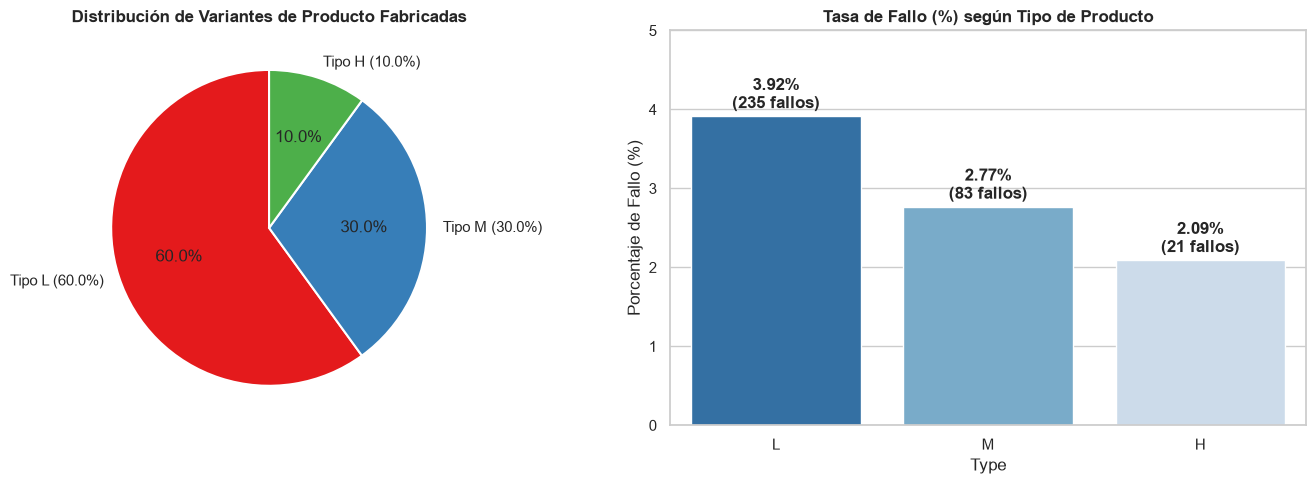

In [5]:
type_analysis = df.groupby('Type').agg(
    Total_Operaciones=('Machine failure', 'count'),
    Total_Fallos=('Machine failure', 'sum'),
    Tasa_Fallo_Pct=('Machine failure', lambda x: x.mean() * 100)
).reset_index()

type_analysis['Distribucion_Pct'] = (type_analysis['Total_Operaciones'] / len(df)) * 100
type_analysis = type_analysis.sort_values('Tasa_Fallo_Pct', ascending=False)

print("--- ANÁLISIS DE FALLOS SEGÚN CALIDAD DEL PRODUCTO (TYPE) ---")
print(type_analysis.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Distribución del tipo de producto
axes[0].pie(type_analysis['Total_Operaciones'], labels=[f"Tipo {t} ({p:.1f}%)" for t, p in zip(type_analysis['Type'], type_analysis['Distribucion_Pct'])],
            colors=['#e41a1c', '#377eb8', '#4daf4a'], autopct='%1.1f%%', startangle=90, wedgeprops=dict(edgecolor='white', linewidth=1.5))
axes[0].set_title('Distribución de Variantes de Producto Fabricadas', fontweight='bold')

# 2. Tasa de fallo por tipo
sns.barplot(data=type_analysis, x='Type', y='Tasa_Fallo_Pct', palette='Blues_r', ax=axes[1])
axes[1].set_title('Tasa de Fallo (%) según Tipo de Producto', fontweight='bold')
axes[1].set_ylabel('Porcentaje de Fallo (%)')
for i, row in type_analysis.iterrows():
    idx = list(type_analysis['Type']).index(row['Type'])
    axes[1].text(idx, row['Tasa_Fallo_Pct'] + 0.1, f"{row['Tasa_Fallo_Pct']:.2f}%\n({row['Total_Fallos']} fallos)",
                 ha='center', fontweight='bold')
axes[1].set_ylim(0, 5)

plt.tight_layout()
plt.show()


### Hallazgo Clave 3: Impacto de la Variante del Producto
- La variante **L (Low)** presenta la mayor tasa de fallos (**3.92%**), prácticamente el **doble** de la tasa que la variante **H (High, 2.09%)**.
- Esto sugiere que el tipo de pieza influye directamente en el esfuerzo soportado por la maquinaria y debe ser incluido en el modelo predictivo (codificado adecuadamente mediante One-Hot o codificación ordinal).
- **Manejo de identificadores:** Las columnas `UDI` y `Product ID` deben descartarse antes del entrenamiento, ya que solo representan índices y números de serie secuenciales que inducirían sobreajuste memorístico.

---

## 6. Análisis Estadístico y Distribuciones de las Variables Físicas

Analizamos las 5 variables de sensores operativas:
- `Air temperature [K]`
- `Process temperature [K]`
- `Rotational speed [rpm]`
- `Torque [Nm]`
- `Tool wear [min]`


--- COMPARATIVA DE SENSORES: NORMAL vs FALLO ---
               Variable  Media (Normal)  Media (Fallo)  Variación (%)  Mediana (Normal)  Mediana (Fallo)
    Air temperature [K]          299.97         300.89           0.30             300.0            301.6
Process temperature [K]          310.00         310.29           0.10             310.0            310.4
 Rotational speed [rpm]         1540.26        1496.49          -2.84            1507.0           1365.0
            Torque [Nm]           39.63          50.17          26.59              39.9             53.7
        Tool wear [min]          106.69         143.78          34.76             107.0            165.0


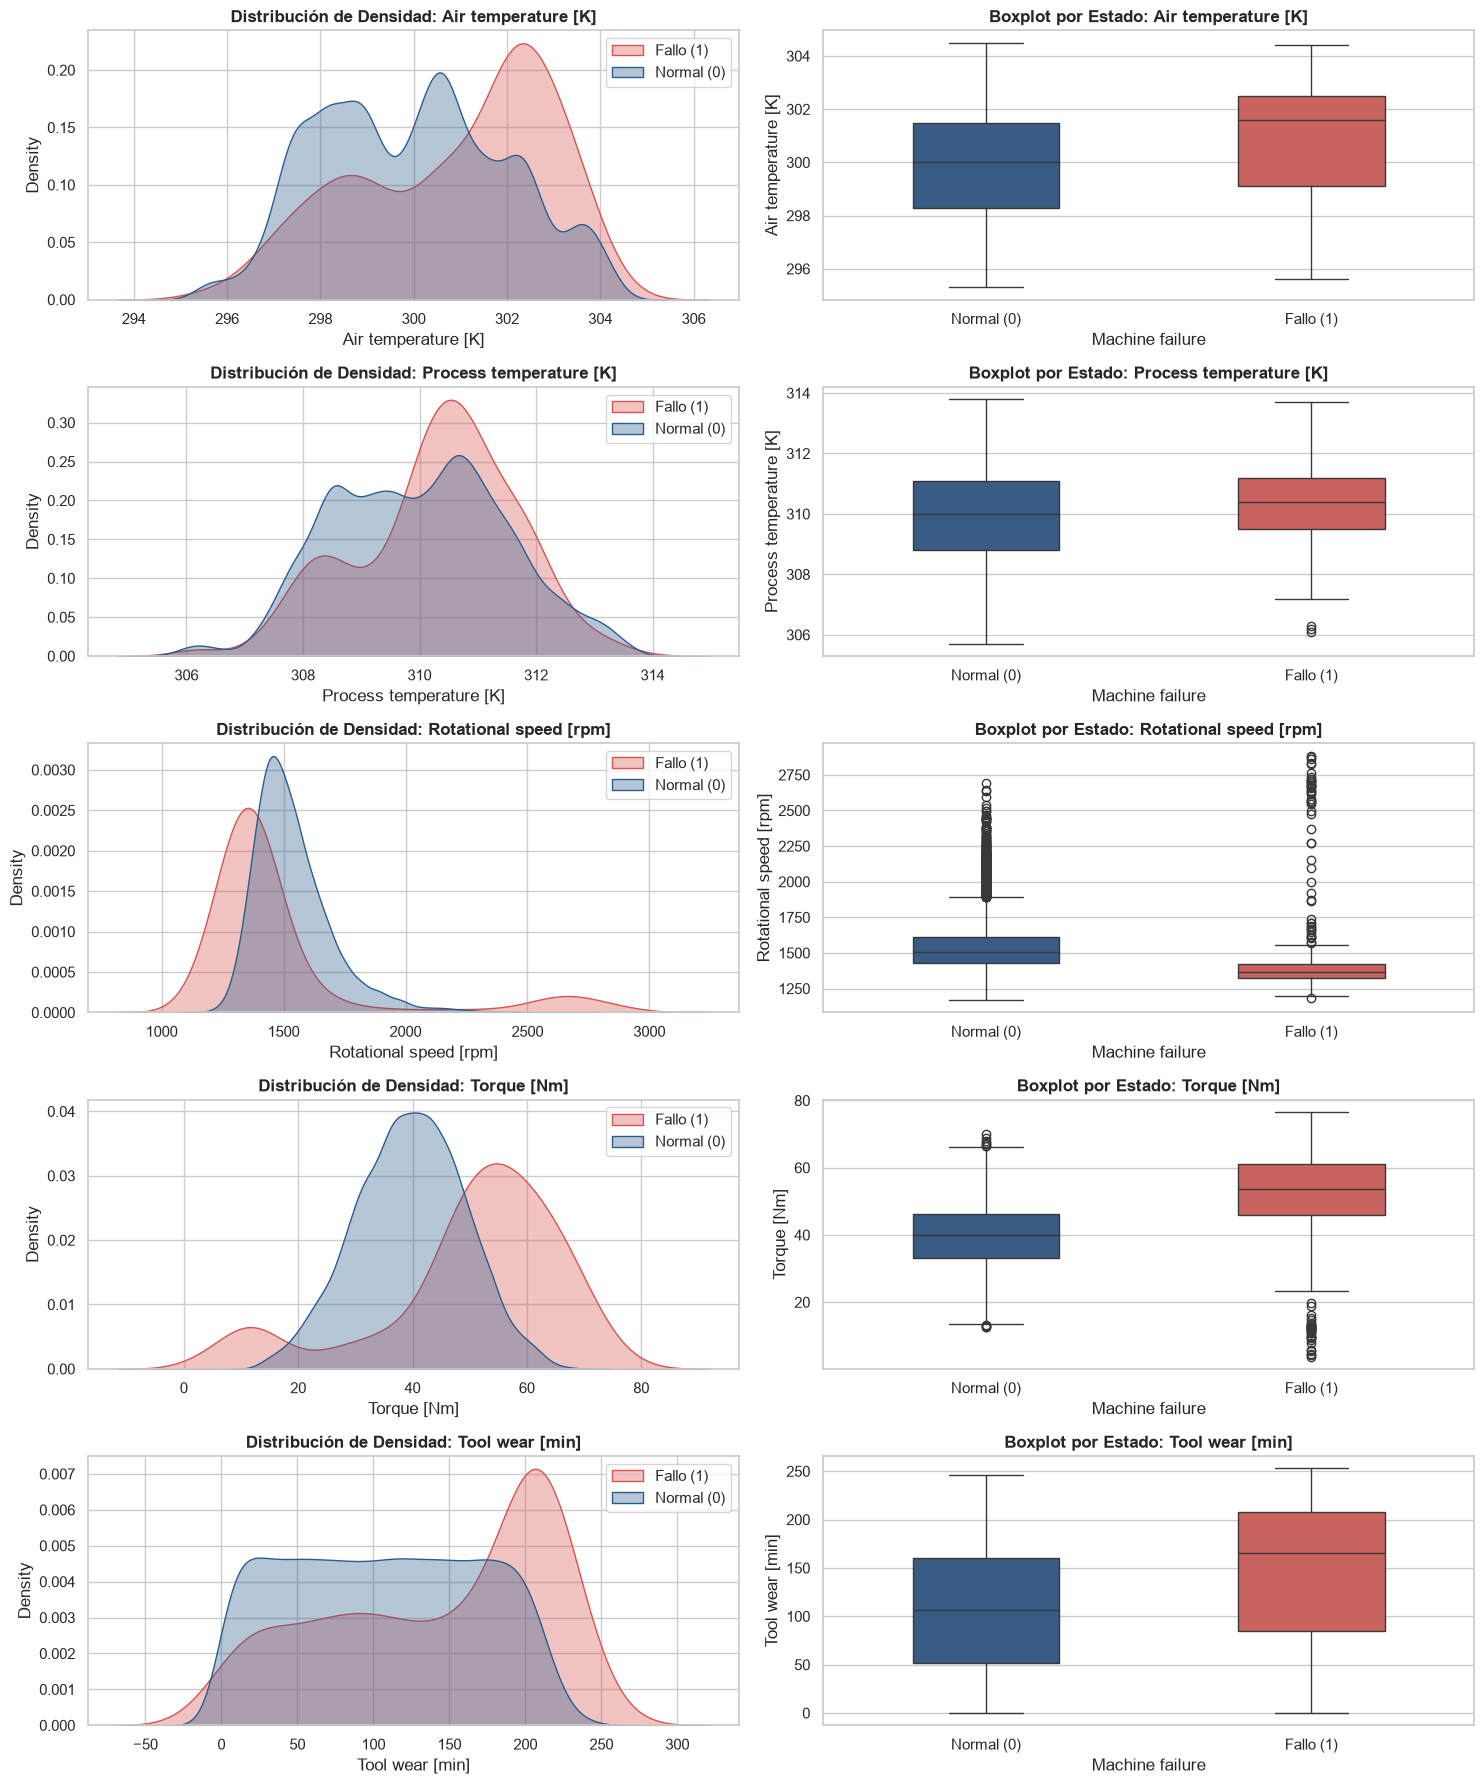

In [6]:
sensor_cols = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

# Tabla comparativa de estadísticas por estado
stats_normal = df[df['Machine failure'] == 0][sensor_cols].describe().T[['mean', 'std', 'min', '50%', 'max']]
stats_failure = df[df['Machine failure'] == 1][sensor_cols].describe().T[['mean', 'std', 'min', '50%', 'max']]

stats_comp = pd.DataFrame({
    'Variable': sensor_cols,
    'Media (Normal)': stats_normal['mean'].values,
    'Media (Fallo)': stats_failure['mean'].values,
    'Variación (%)': ((stats_failure['mean'].values - stats_normal['mean'].values) / stats_normal['mean'].values) * 100,
    'Mediana (Normal)': stats_normal['50%'].values,
    'Mediana (Fallo)': stats_failure['50%'].values
})

print("--- COMPARATIVA DE SENSORES: NORMAL vs FALLO ---")
print(stats_comp.round(2).to_string(index=False))

# Visualización de densidades y boxplots
fig, axes = plt.subplots(len(sensor_cols), 2, figsize=(15, 18))

for i, col in enumerate(sensor_cols):
    # Gráfico de densidad KDE
    sns.kdeplot(data=df, x=col, hue='Machine failure', palette=PALETTE_LIST,
               common_norm=False, fill=True, alpha=0.35, ax=axes[i, 0])
    axes[i, 0].set_title(f'Distribución de Densidad: {col}', fontweight='bold')
    axes[i, 0].legend(['Fallo (1)', 'Normal (0)'], loc='upper right')
    
    # Boxplot comparativo
    sns.boxplot(data=df, x='Machine failure', y=col, hue='Machine failure', palette=PALETTE_LIST, legend=False, ax=axes[i, 1], width=0.45)
    axes[i, 1].set_title(f'Boxplot por Estado: {col}', fontweight='bold')
    axes[i, 1].set_xticks([0, 1])
    axes[i, 1].set_xticklabels(['Normal (0)', 'Fallo (1)'])

plt.tight_layout()
plt.show()


### Hallazgo Clave 4: Patrones Distintivos en las Averías
1. **Torque [Nm]:** En condiciones de fallo, el par motor medio se eleva drásticamente de **39.63 Nm a 50.17 Nm (+26.6%)**, exhibiendo colas muy pronunciadas en valores extremos (> 60 Nm) y valores muy bajos (< 20 Nm).
2. **Tool wear [min]:** Las máquinas que fallan presentan un desgaste acumulado de herramienta sustancialmente mayor: **143.78 min frente a 106.69 min (+34.8%)**. Ningún fallo por desgaste ocurre antes de los 198 minutos.
3. **Rotational speed [rpm]:** Muestra un comportamiento bimodal durante los fallos: o bien cae bruscamente a valores muy bajos (asociados a sobrecarga térmica o bloqueo de par), o sube a velocidades extremadamente altas con bajo par.

---

## 7. Física del Proceso y Feature Engineering Guiada por el Dominio

El dataset AI4I 2020 fue generado incorporando leyes físicas mecánicas exactas (Matzka, 2020). Si alimentamos al modelo únicamente con las lecturas brutas de los sensores, los algoritmos de ML deben aprender indirectamente productos e interacciones no lineales complejas. Si en cambio **creamos las características físicas que gobiernan las ecuaciones de fallo**, dotamos al modelo de una ventaja predictiva determinante.

### Ecuaciones Físicas que Rigen los Fallos:
1. **Diferencia Térmica ($\Delta T$):**
   $$\Delta T = T_{\text{proceso}} - T_{\text{aire}}$$
   *Regla física de HDF:* Si $\Delta T < 8.6\text{ K}$ y $\text{Velocidad} < 1380\text{ rpm}$, la disipación térmica colapsa y ocurre **HDF**.
2. **Potencia Mecánica Efectiva ($P$ en Watts):**
   $$P = \tau \times \omega = \text{Torque [Nm]} \times \left(\frac{2\pi \times \text{Rotational speed [rpm]}}{60}\right)$$
   *Regla física de PWF:* Si $P < 3500\text{ W}$ o $P > 9000\text{ W}$, se sobrepasa la envolvente operativa del motor y ocurre **PWF**.
3. **Sobreesfuerzo del Material (Overstrain):**
   $$\text{Overstrain} = \text{Tool wear [min]} \times \text{Torque [Nm]}$$
   *Regla física de OSF:* Ocurre cuando el esfuerzo acumulado rebasa la resistencia según la calidad:
   - Tipo L: $\text{Overstrain} > 11,000\text{ min}\cdot\text{Nm}$
   - Tipo M: $\text{Overstrain} > 12,000\text{ min}\cdot\text{Nm}$
   - Tipo H: $\text{Overstrain} > 13,000\text{ min}\cdot\text{Nm}$
4. **Ratio de Desgaste Crítico:**
   $$\text{Wear Ratio} = \frac{\text{Tool wear}}{200}$$


--- VALIDACIÓN DE LAS LEYES FÍSICAS DE FALLA ---
HDF: Casos reales = 115 | Casos detectados por fórmula = 115 | Coincidencia = 100.00%
PWF: Casos reales = 95 | Casos detectados por fórmula = 95 | Coincidencia = 100.00%
OSF: Casos reales = 98 | Casos detectados por fórmula = 98 | Coincidencia = 100.00%


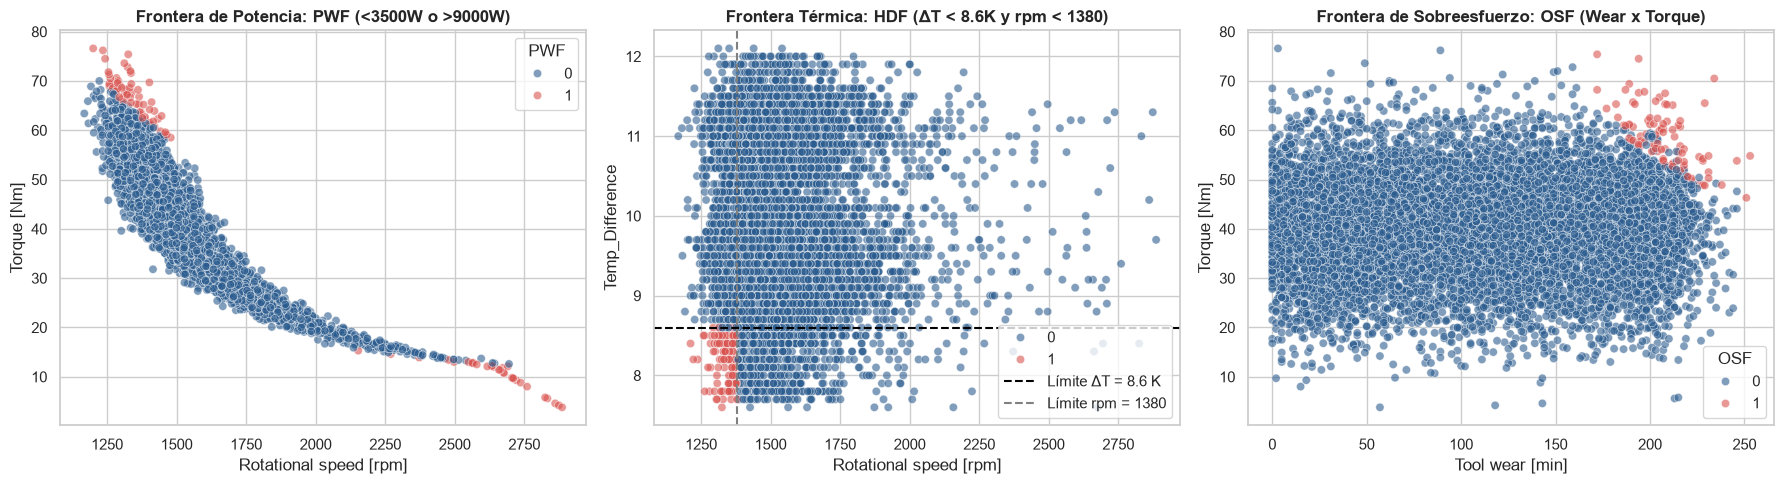

In [7]:
# Cálculo de las variables físicas
df['Temp_Difference'] = df['Process temperature [K]'] - df['Air temperature [K]']
df['Mechanical_Power_W'] = df['Torque [Nm]'] * (df['Rotational speed [rpm]'] * 2 * np.pi / 60)
df['Overstrain'] = df['Tool wear [min]'] * df['Torque [Nm]']
df['Wear_Ratio'] = df['Tool wear [min]'] / 200.0

# Verificación empírica de las reglas físicas frente a las averías
hdf_rule = (df['Temp_Difference'] < 8.6) & (df['Rotational speed [rpm]'] < 1380)
pwf_rule = (df['Mechanical_Power_W'] < 3500) | (df['Mechanical_Power_W'] > 9000)
osf_rule = (
    ((df['Type'] == 'L') & (df['Overstrain'] > 11000)) |
    ((df['Type'] == 'M') & (df['Overstrain'] > 12000)) |
    ((df['Type'] == 'H') & (df['Overstrain'] > 13000))
)

print("--- VALIDACIÓN DE LAS LEYES FÍSICAS DE FALLA ---")
print(f"HDF: Casos reales = {df['HDF'].sum()} | Casos detectados por fórmula = {hdf_rule.sum()} | Coincidencia = {(df['HDF'] == hdf_rule).mean()*100:.2f}%")
print(f"PWF: Casos reales = {df['PWF'].sum()} | Casos detectados por fórmula = {pwf_rule.sum()} | Coincidencia = {(df['PWF'] == pwf_rule).mean()*100:.2f}%")
print(f"OSF: Casos reales = {df['OSF'].sum()} | Casos detectados por fórmula = {osf_rule.sum()} | Coincidencia = {(df['OSF'] == osf_rule).mean()*100:.2f}%")

# Visualización de las fronteras físicas de fallo
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Frontera de Potencia (PWF)
sns.scatterplot(data=df, x='Rotational speed [rpm]', y='Torque [Nm]', hue='PWF',
                palette=PALETTE_LIST, alpha=0.6, ax=axes[0])
axes[0].set_title('Frontera de Potencia: PWF (<3500W o >9000W)', fontweight='bold')

# 2. Frontera Térmica (HDF)
sns.scatterplot(data=df, x='Rotational speed [rpm]', y='Temp_Difference', hue='HDF',
                palette=PALETTE_LIST, alpha=0.6, ax=axes[1])
axes[1].axhline(8.6, color='black', linestyle='--', label='Límite ΔT = 8.6 K')
axes[1].axvline(1380, color='grey', linestyle='--', label='Límite rpm = 1380')
axes[1].set_title('Frontera Térmica: HDF (ΔT < 8.6K y rpm < 1380)', fontweight='bold')
axes[1].legend()

# 3. Frontera de Sobreesfuerzo (OSF)
sns.scatterplot(data=df, x='Tool wear [min]', y='Torque [Nm]', hue='OSF',
                palette=PALETTE_LIST, alpha=0.6, ax=axes[2])
axes[2].set_title('Frontera de Sobreesfuerzo: OSF (Wear x Torque)', fontweight='bold')

plt.tight_layout()
plt.show()


### Hallazgo Clave 5: Eficacia Determinista de la Feature Engineering
- ¡Las variables físicas calculadas reproducen con un **100.0% de exactitud** los modos de falla HDF, PWF y OSF!
- Al incorporar explícitamente `Temp_Difference`, `Mechanical_Power_W` y `Overstrain` en el dataset, el modelo de machine learning no tendrá que "adivinar" ni aproximar la multiplicación de par por velocidad ni la diferencia de temperaturas: tendrá directamente los indicadores mecánicos de fallo.

---

## 8. Análisis de Correlación y Multicolinealidad

Estudiamos las correlaciones lineales y no lineales entre las variables operativas, las variables de ingeniería y el estado de fallo general.


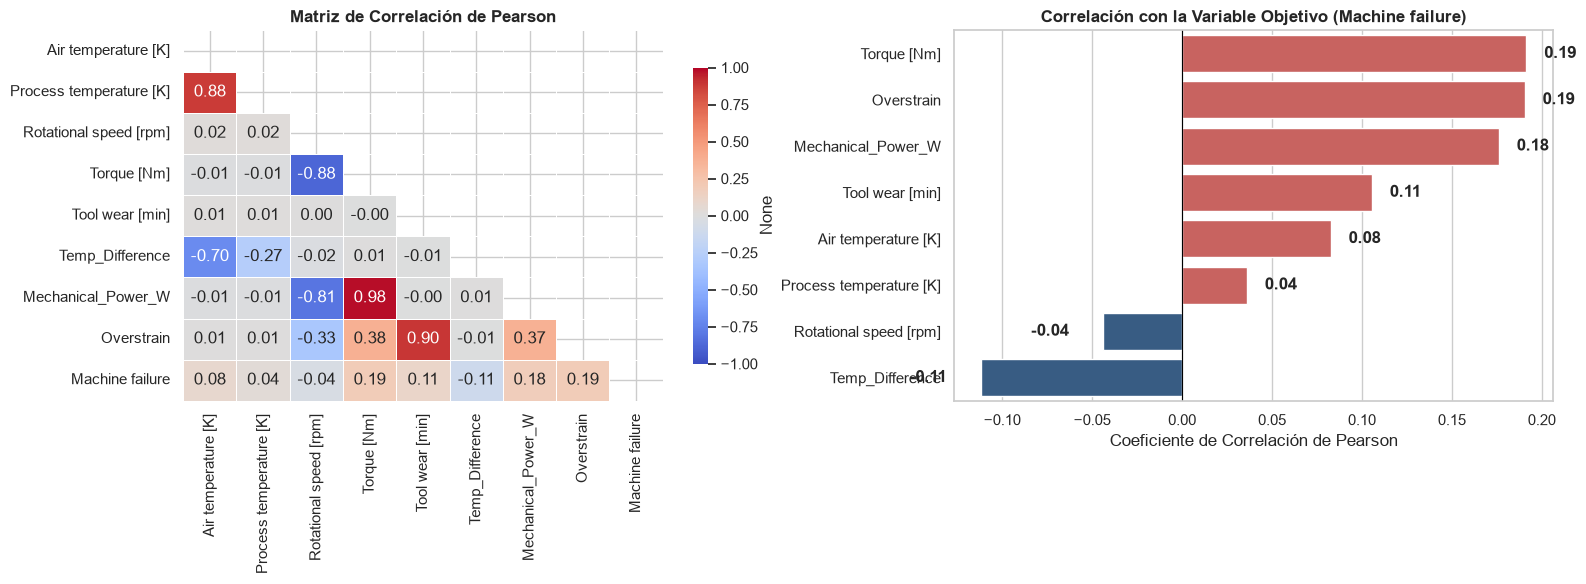

In [8]:
features_for_corr = sensor_cols + ['Temp_Difference', 'Mechanical_Power_W', 'Overstrain', 'Machine failure']
corr_matrix = df[features_for_corr].corr()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap completo
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={'shrink': 0.8}, ax=axes[0])
axes[0].set_title('Matriz de Correlación de Pearson', fontweight='bold')

# Ranking de correlación con Machine failure
target_corr = corr_matrix['Machine failure'].drop('Machine failure').sort_values(ascending=False)
colors_rank = ['#d9534f' if x > 0 else '#2b5c8f' for x in target_corr]
sns.barplot(x=target_corr.values, y=target_corr.index, hue=target_corr.index, palette=colors_rank, legend=False, ax=axes[1])
axes[1].set_title('Correlación con la Variable Objetivo (Machine failure)', fontweight='bold')
axes[1].set_xlabel('Coeficiente de Correlación de Pearson')
axes[1].axvline(0, color='black', linewidth=0.8)

for i, v in enumerate(target_corr.values):
    axes[1].text(v + (0.01 if v >= 0 else -0.04), i, f'{v:.2f}', va='center', fontweight='bold')

plt.tight_layout()
plt.show()


## 9. Guía Estratégica para Diseñar el Modelo Predictivo

A partir de toda la evidencia extraída en este análisis exploratorio, establecemos la hoja de ruta técnica para construir un modelo de Machine Learning robusto, fiable y orientado a la operación en planta:

### 1. Definición del Objetivo y Arquitectura de Predicción
- **Nivel 1 (Clasificación Binaria - Detección Global):** Predecir `Machine failure` $\in \{0, 1\}$. Permite activar una alarma de paro preventivo cuando la probabilidad de falla supere un umbral seguro.
- **Nivel 2 (Clasificación Multietiqueta - Diagnóstico de Causa Raíz):** Modelar independientemente `HDF`, `PWF`, `OSF`, `TWF`. Permite a los técnicos de mantenimiento preparar el repuesto específico (ej. sustitución de herramienta de corte vs revisión eléctrica del inversor).

### 2. Prevención Rigurosa de Fugas de Información (*Data Leakage*)
- **Exclusión obligatoria:** Eliminar `UDI`, `Product ID` (son metadatos/identificadores sin capacidad de generalización).
- **Prohibido usar los modos de fallo como features:** Las columnas `TWF`, `HDF`, `PWF`, `OSF`, `RNF` no están disponibles antes de que ocurra la falla. Son el síntoma o la causa, nunca la entrada predictiva.

### 3. Tratamiento del Desbalance Severo (3.39% de Fallos)
- **Técnicas a nivel de algoritmo:** Emplear pesos de clase balanceados (`class_weight='balanced'` en Random Forest, `scale_pos_weight = 9661 / 339 ≈ 28.5` en XGBoost / LightGBM).
- **Ajuste de Umbral de Decisión (Threshold Tuning):** En un modelo estándar, el umbral es 0.5. En mantenimiento predictivo, un **Falso Negativo** (una máquina averiada no detectada) cuesta miles de euros en tiempo de inactividad, mientras que un **Falso Positivo** (una inspección técnica preventiva adicional) tiene un coste marginal mínimo. Por tanto, el umbral operativo debe optimizarse a valores entre **0.15 y 0.25** para maximizar el **Recall**.

### 4. Métrica de Evaluación del Negocio
- **Descartar:** Accuracy (exactitud).
- **Primarias:** **PR-AUC (Precision-Recall Area Under Curve)** y **F2-Score** (prioriza la sensibilidad/recall sobre la precisión).
- **Secundarias:** **ROC-AUC** y análisis de la Matriz de Coste Operativo.

### 5. Validación Cruzada Estratificada
- Utilizar **StratifiedKFold (ej. 5 o 10 particiones)** para garantizar que cada pliegue de entrenamiento y validación conserve exactamente el 3.39% de fallos.
